**practica #5:**

**Introducción al análisis frecuencial de señales**

**presentado por:**
Karly Tarazona, Luis Montoya 

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

1.	Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. 

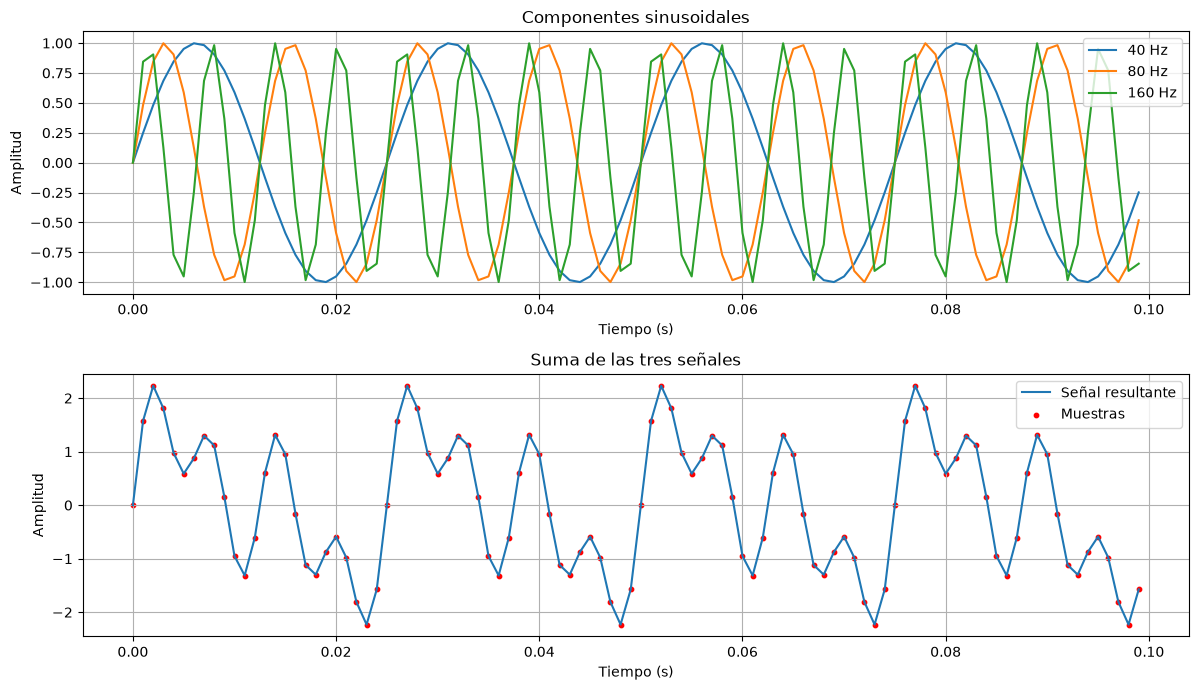

Frecuencia mínima: 320 Hz
Frecuencia utilizada: 1000 Hz


In [33]:

# Frecuencias de las componentes
f1 = 40
f2 = 80
f3 = 160

# Frecuencia mínima de Nyquist
fs_min = 2 * max(f1, f2, f3)

# Frecuencia de muestreo seleccionada
fs = 1000

# Vector de tiempo (0.1 segundos)
t = np.arange(0, 0.1, 1/fs)

# Componentes sinusoidales
x1 = np.sin(2 * np.pi * f1 * t)
x2 = np.sin(2 * np.pi * f2 * t)
x3 = np.sin(2 * np.pi * f3 * t)

# Señal resultante
x = x1 + x2 + x3

# Gráficas
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x1, label="40 Hz")
plt.plot(t, x2, label="80 Hz")
plt.plot(t, x3, label="160 Hz")
plt.title("Componentes sinusoidales")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, x, label="Señal resultante")
plt.scatter(t, x, s=10, color="red", label="Muestras")
plt.title("Suma de las tres señales")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Frecuencia mínima:", fs_min, "Hz")
print("Frecuencia utilizada:", fs, "Hz")


Se creó una señal mediante la suma de tres componentes sinusoidales de 40 Hz, 80 Hz y 160 Hz. Aplicando el teorema de Nyquist-Shannon, se determinó que la frecuencia mínima teórica de muestreo es de 320 Hz. No obstante, se seleccionó una frecuencia de 1000 Hz para obtener una representación digital más adecuada de la señal, con mayor cantidad de muestras y evitando las limitaciones de trabajar exactamente en la frecuencia de Nyquist.

2.	Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).

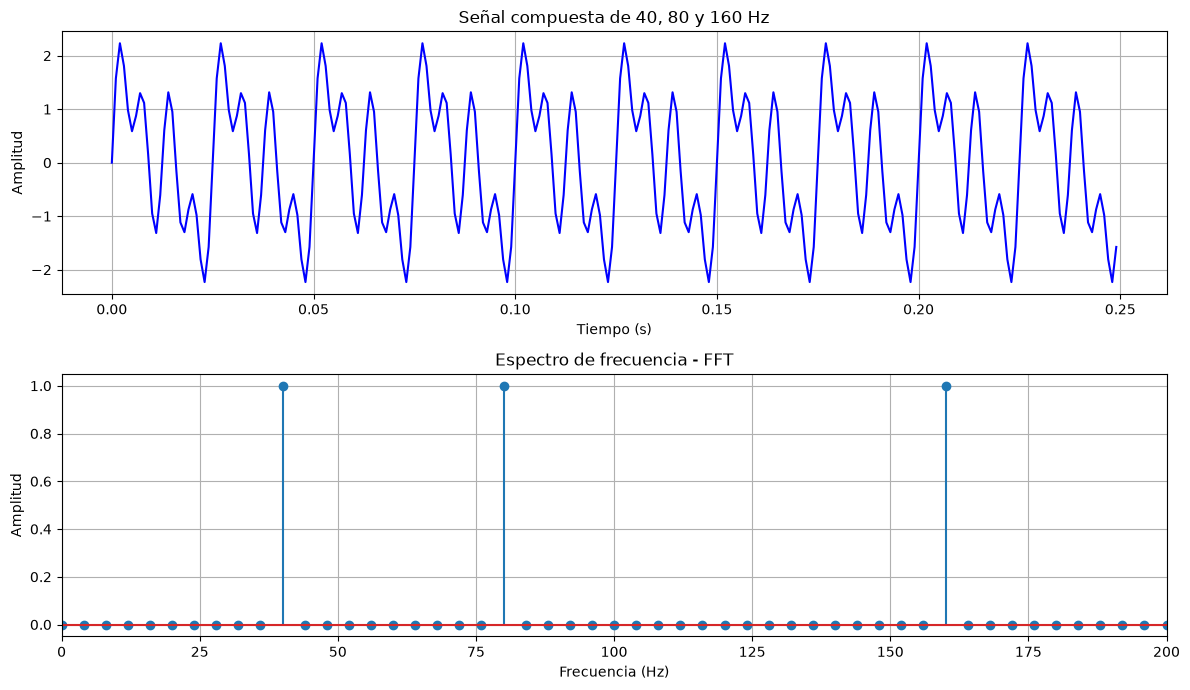

Muestras de tiempo: 250
Muestras de la señal: 250
Número de muestras FFT: 250
Resolución en frecuencia: 4.0 Hz


In [34]:
# Frecuencias de las componentes
f1 = 40
f2 = 80
f3 = 160

# Parámetros de muestreo
Fs = 1000
Fo = 40
Tp = 1/Fo
T = 1/Fs

# Vector de tiempo para 10 períodos
t = np.arange(0, 10*Tp, T)

# CREAR NUEVAMENTE LA SEÑAL ORIGINAL
x = (np.sin(2*np.pi*f1*t) +
     np.sin(2*np.pi*f2*t) +
     np.sin(2*np.pi*f3*t))

# Calcular la Transformada de Fourier
X = np.fft.fft(x)

# Número de muestras
N = len(X)

# Eje de frecuencias
F = np.arange(0, N)*Fs/N

# Seleccionar la mitad positiva del espectro
Nmitad = N//2 + 1
Fmitad = F[0:Nmitad]
Xmitad = X[0:Nmitad]

# Normalizar amplitudes
amplitud = 2*np.abs(Xmitad)/N
amplitud[0] /= 2

if N % 2 == 0:
    amplitud[-1] /= 2

# Graficar señal original y espectro
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal compuesta de 40, 80 y 160 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.stem(Fmitad, amplitud)
plt.title('Espectro de frecuencia - FFT')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 200)
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar resultados
print("Muestras de tiempo:", len(t))
print("Muestras de la señal:", len(x))
print("Número de muestras FFT:", N)
print("Resolución en frecuencia:", Fs/N, "Hz")


3.	Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal 

La Transformada Inversa de Fourier permite reconstruir una señal en el dominio del tiempo a partir de su representación en el dominio de la frecuencia.
En Python, la función que permite realizar este cálculo es **`np.fft.ifft()`**. Donde \(N\) representa el número de muestras y \(X[k]\) los coeficientes de Fourier [1]

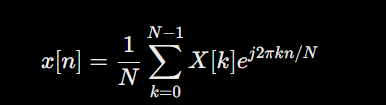

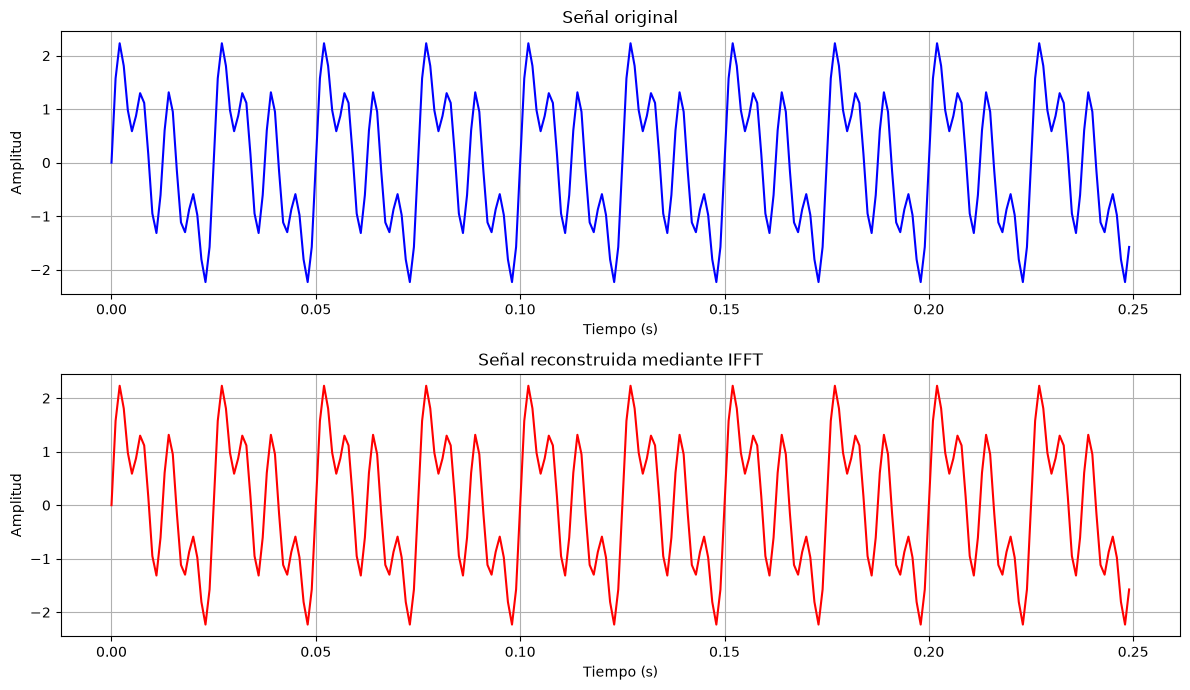

Error máximo de reconstrucción: 8.881784197001252e-16


In [35]:
# Transformada inversa de Fourier
xr = np.fft.ifft(X)

# Parte real de la señal reconstruida
xr = np.real(xr)

# Comparación gráfica
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal original')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, xr, color='red')
plt.title('Señal reconstruida mediante IFFT')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar el error de reconstrucción
error = np.max(np.abs(x - xr))
print("Error máximo de reconstrucción:", error)

se comprobó que es posible transformar una señal del dominio del tiempo al dominio de la frecuencia y posteriormente recuperarla sin pérdida apreciable de información. Las señales original y reconstruida presentan un comportamiento prácticamente idéntico, con diferencias numéricas cercanas a cero. Esto demuestra la utilidad de la transformada inversa en el procesamiento digital de señales y constituye la base para aplicar técnicas de filtrado frecuencial

4.	¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?

C:\Users\Juan Felipe\AppData\Local\Temp\ipykernel_21576\2457393857.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  F2[9:13] = F1[9:13];


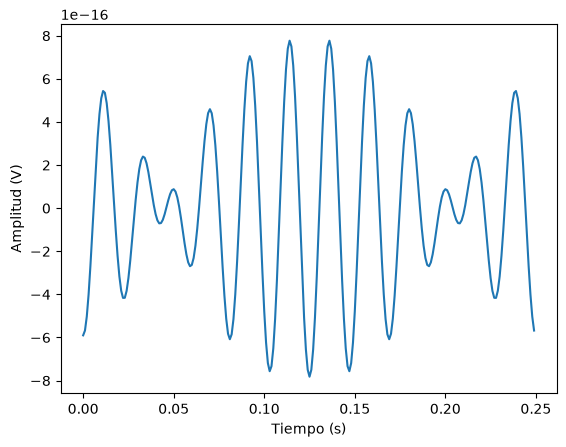

In [36]:
F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()


Sí. El código realiza un filtrado en el dominio de la frecuencia, porque selecciona determinados coeficientes de la Transformada de Fourier y elimina los demás.

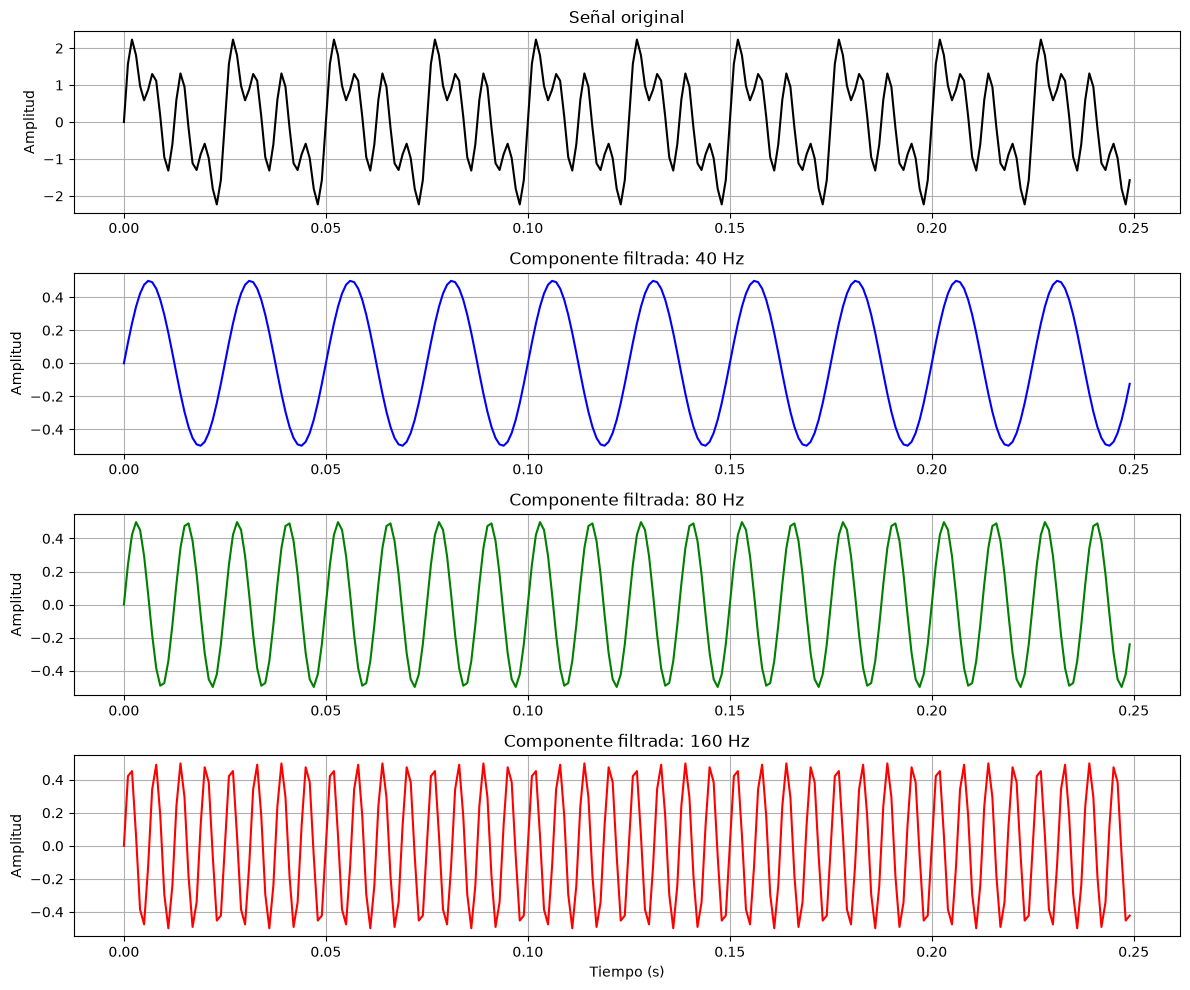

Error máximo: 1.1154543260348764


In [37]:

# Filtrar componente de 40 Hz
F40 = np.zeros(N, dtype=complex)
F40[np.isclose(np.abs(F), 40)] = F1[
    np.isclose(np.abs(F), 40)
]
x40 = np.real(np.fft.ifft(F40))

# Filtrar componente de 80 Hz
F80 = np.zeros(N, dtype=complex)
F80[np.isclose(np.abs(F), 80)] = F1[
    np.isclose(np.abs(F), 80)
]
x80 = np.real(np.fft.ifft(F80))

# Filtrar componente de 160 Hz
F160 = np.zeros(N, dtype=complex)
F160[np.isclose(np.abs(F), 160)] = F1[
    np.isclose(np.abs(F), 160)
]
x160 = np.real(np.fft.ifft(F160))

# Graficar resultados
plt.figure(figsize=(12, 10))

plt.subplot(4, 1, 1)
plt.plot(t, x, color='black')
plt.title('Señal original')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, x40, color='blue')
plt.title('Componente filtrada: 40 Hz')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x80, color='green')
plt.title('Componente filtrada: 80 Hz')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(t, x160, color='red')
plt.title('Componente filtrada: 160 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar reconstrucción
x_reconstruida = x40 + x80 + x160

error = np.max(np.abs(x - x_reconstruida))
print("Error máximo:", error)


El código propuesto aplica un filtro en el dominio de la frecuencia, ya que permite seleccionar determinados coeficientes de la Transformada Discreta de Fourier y eliminar las componentes no deseadas. A través de este procedimiento se logró extraer individualmente las señales de 40 Hz, 80 Hz y 160 Hz, conservando los coeficientes correspondientes a sus frecuencias positivas y negativas. Posteriormente, mediante la Transformada Inversa de Fourier, se reconstruyó cada componente en el dominio del tiempo. Los resultados demuestran que el análisis frecuencial permite separar señales de distintas frecuencias y recuperar sus características originales

5.	Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo e una de las señales construidas anteriormente.

El método de Welch sirve para determinar cómo se distribuye la potencia de una señal entre diferentes frecuencias. [2]

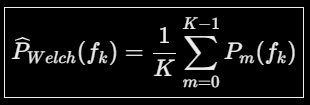

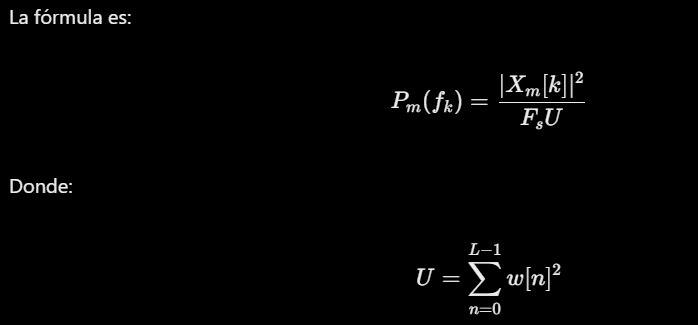

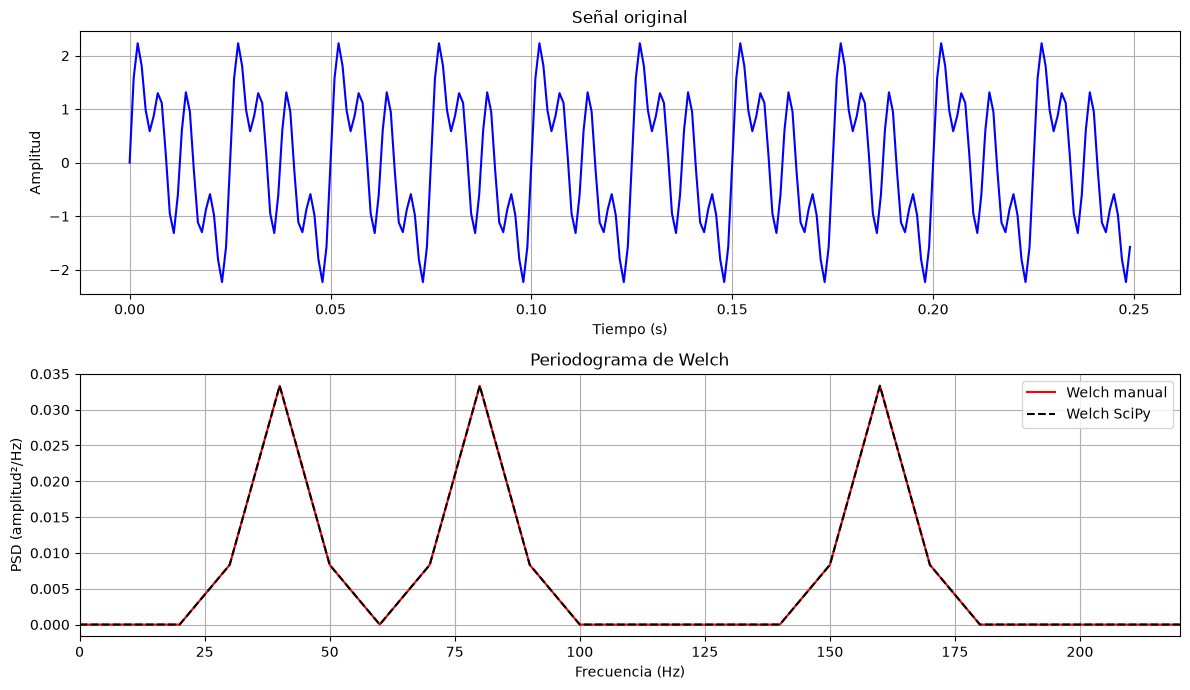

Frecuencias de interés: 40, 80 y 160 Hz
Número de segmentos: 4
Resolución: 10.0 Hz
Error máximo frente a SciPy: 1.3877787807814457e-17
40 Hz: PSD = 0.033333
80 Hz: PSD = 0.033333
160 Hz: PSD = 0.033333


In [38]:
from scipy.signal import welch

# 2. Función manual del periodograma de Welch
def welch_manual(x, Fs, L=100, solapamiento=50):

    N = len(x) # nuemro total de muestra
    paso = L - solapamiento  #desplazamiento entre muestras

    if L > N or L <= 0:
        raise ValueError("Tamaño de segmento inválido")

    if paso <= 0 or solapamiento < 0:
        raise ValueError("Solapamiento inválido")

    # Crear ventana Hann periódica
    n = np.arange(L)
    ventana = 0.5 - 0.5*np.cos(2*np.pi*n/L)

    # Normalización de potencia de la ventana
    U = np.sum(ventana**2)

    periodogramas = []

    # Dividir la señal en segmentos
    for inicio in range(0, N-L+1, paso):

        segmento = x[inicio:inicio+L]

        # Aplicar ventana Hann
        segmento_ventana = segmento * ventana

        # Calcular DFT mediante FFT
        X = np.fft.fft(segmento_ventana)

        # Calcular periodograma bilateral
        P = (np.abs(X)**2) / (Fs*U)

        # Convertir a espectro unilateral
        P = P[:L//2+1]

        if L % 2 == 0:
            P[1:-1] *= 2
        else:
            P[1:] *= 2

        periodogramas.append(P)

    # Promediar todos los periodogramas
    PSD = np.mean(periodogramas, axis=0)

    # Crear eje de frecuencias
    frecuencias = np.fft.rfftfreq(L, d=1/Fs)

    return frecuencias, PSD

# 3. Aplicar nuestra función
F_manual, P_manual = welch_manual(x, Fs)

# 4. Comparar con la función de SciPy
F_scipy, P_scipy = welch(
    x,
    fs=Fs,
    window='hann',
    nperseg=100,
    noverlap=50,
    detrend=False,
    scaling='density'
)

# 5. Graficar
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal original')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(F_manual, P_manual,
         label='Welch manual', color='red')
plt.plot(F_scipy, P_scipy, '--',
         label='Welch SciPy', color='black')

plt.title('Periodograma de Welch')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('PSD (amplitud²/Hz)')
plt.xlim(0, 220)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 6. Verificar resultados
print("Frecuencias de interés: 40, 80 y 160 Hz")
print("Número de segmentos:", 4)
print("Resolución:", Fs/100, "Hz")
print("Error máximo frente a SciPy:",
      np.max(np.abs(P_manual-P_scipy)))

for f in [40, 80, 160]:
    i = np.argmin(np.abs(F_manual-f))
    print(f"{f} Hz: PSD = {P_manual[i]:.6f}")


Se tomó la señal en segmentos parcialmente superpuestos, y se aplico una ventana Hann. Se procedio a calcular la transformada de cada segmento, obtener su densidad espectral de potencia y promediar los resultados. Al aplicar el procedimiento a la señal construida anteriormente, se identificaron correctamente las frecuencias de 40 Hz, 80 Hz y 160 Hz. La comparación con la función Welch de SciPy confirmó la concordancia de los resultados.

6. El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el método de la librería con la función creada en el punto anterior.

In [39]:
#Cargar el archivo .mat
data = loadmat("senecg.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'ECG'])


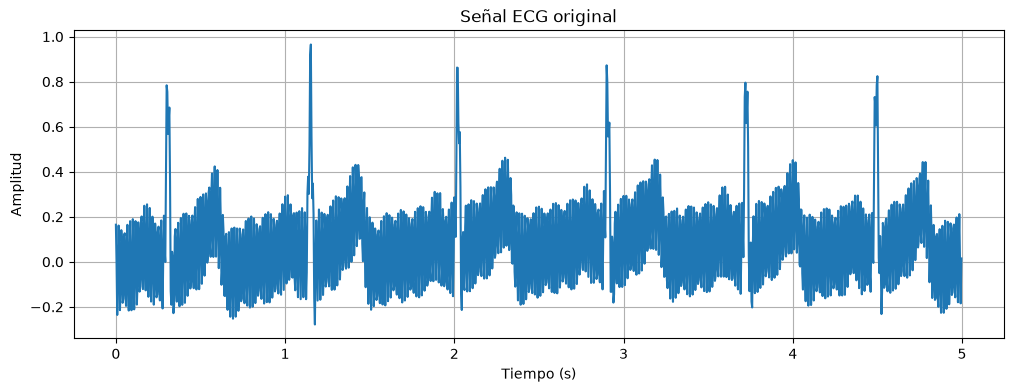

In [40]:
# Se usa el nombre del data.keys que contiene la señal ECG que es "ECG"
x = np.squeeze(data["ECG"])

Fs = 250
T = 1/Fs

t = np.arange(len(x))/Fs

plt.figure(figsize=(12,4))
plt.plot(t, x)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Señal ECG original')
plt.grid()
plt.show()

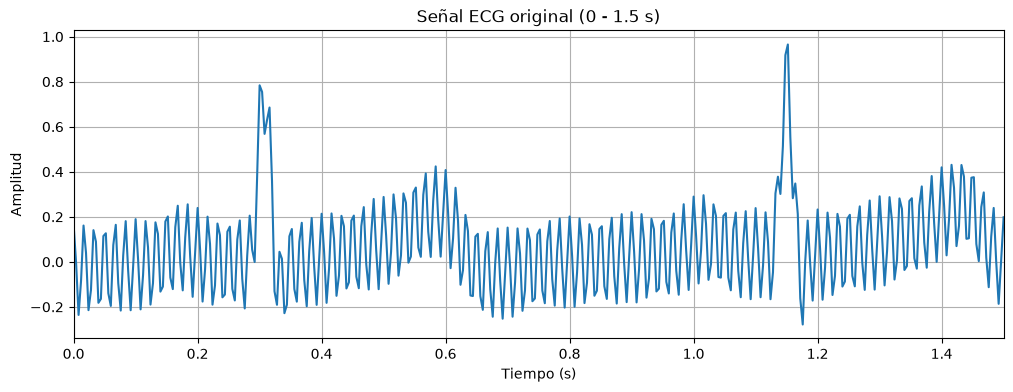

In [41]:
# Seleccionar muestras entre 0 y 0.6 segundos
idx = (t >= 0) & (t <= 1.5)

plt.figure(figsize=(12,4))
plt.plot(t[idx], x[idx])

plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Señal ECG original (0 - 1.5 s)')
plt.xlim(0, 1.5)
plt.grid()
plt.show()

Periodograma de Welch:

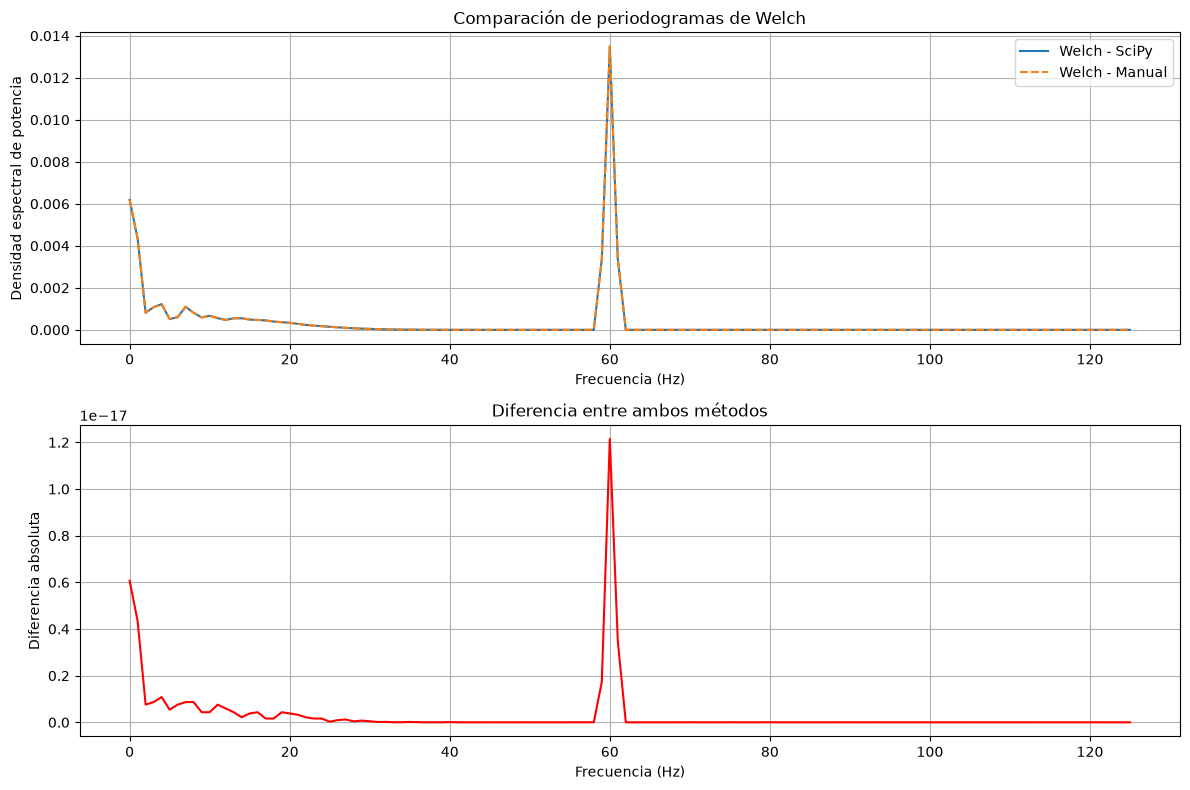

Error máximo: 1.214306433183765e-17
Error relativo: 9.127735254737837e-16


In [42]:
Fs = 250
L = 250
solapamiento = 125

x = np.asarray(x).squeeze()

# Welch manual
f_manual, P_manual = welch_manual(
    x, Fs, L, solapamiento
)


# Welch con SciPy

f_scipy, P_scipy = welch(
    x,
    fs=Fs,
    window='hann',
    nperseg=L,
    noverlap=solapamiento,
    detrend=False,
    return_onesided=True,
    scaling='density'
)



plt.figure(figsize=(12, 8))

# Comparación de los periodogramas
plt.subplot(2, 1, 1)

plt.plot(f_scipy, P_scipy, label='Welch - SciPy')
plt.plot(f_manual, P_manual, '--', label='Welch - Manual')

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia')
plt.title('Comparación de periodogramas de Welch')
plt.legend()
plt.grid()

# Diferencia entre los resultados
plt.subplot(2, 1, 2)

diferencia = np.abs(P_scipy - P_manual)

plt.plot(f_scipy, diferencia, color='red')

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Diferencia absoluta')
plt.title('Diferencia entre ambos métodos')
plt.grid()

plt.tight_layout()
plt.show()



error_maximo = np.max(diferencia)

error_relativo = (
    np.linalg.norm(P_scipy - P_manual) /
    np.linalg.norm(P_scipy)
)

print("Error máximo:", error_maximo)
print("Error relativo:", error_relativo)

Con los resultados obtenidos se puede hacer un análisis de los métodos:
La diferencia absoluta representada en el eje y indica la diferencia que da cada método en cada frecuencia. Se obtienen valores del orden de 10^-19, por lo que se considera una diferencia muy pequeña.
Lo mismo se considera para el error máximo que sería el mayor error o el valor más alto entre todas las diferencias absolutas y el cual consiste en 8.67 *10^-19 y el error relativo 2.01 *10^-19 que consiste en la diferencia global de ambos métodos. Como se observa, ambos errores al igual que la diferencia absoluta muestran valores muy pequeños que corresponden a una diferencia muy pequeña.

Para las funciones de Welch se tiene Fs=250 Hz y L=250 para tener una resolución de 1 Hz y poder distinguir mejor variaciones pequeñas ya que en frecuencias bajas (0 a 20 Hz) se observó ruido que estaba mejor definido que si se usaban valores de L más pequeños.

**Análisis Periodograma de Welch:**
Se observan varios picos en el periodograma. Lo que destaca principalmente es el pico de 60 Hz que es el de mayor amplitud y corresponde a la red eléctrica de colombia [3], este se filtrará con seguridad pero queda analizar de las frecuencias menores a 20 Hz qué corresponde a ruido y qué corresponde a información de la señal extraída, el ruido de menor frecuencia puede ser deriva de la línea base, el cuál es un ruido de muy  baja frecuencia que se ve representado como un desvío lento de toda la señal o gran parte de ella.

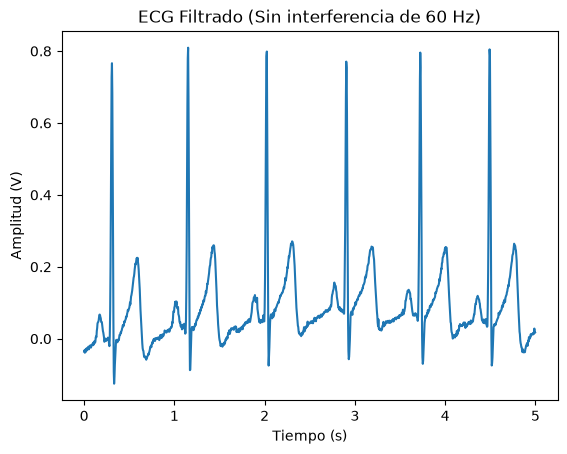

In [43]:
fs = 250 

F1 = np.fft.fft(x)
F2 = F1.copy() 

# Calcular el índice correspondiente a 60 Hz
N = len(x)
idx_60 = int(60 * N / fs)
rango = 2 

# Anular el pico de 60 Hz (frecuencia positiva)
F2[idx_60 - rango : idx_60 + rango + 1] = 0

# Anular la frecuencia simétrica (frecuencia negativa)
F2[-(idx_60 + rango + 1) : -(idx_60 - rango)] = 0

# Reconstruir la señal en el dominio del tiempo
xr = np.fft.ifft(F2)

# Graficar
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)')
plt.title('ECG Filtrado (Sin interferencia de 60 Hz)')
plt.show()

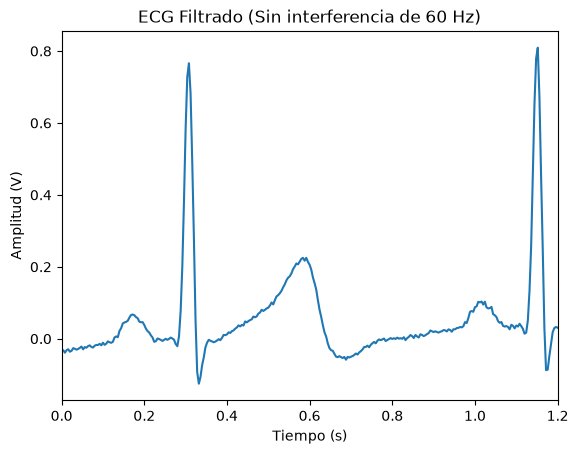

In [44]:
mask = (t >= 0) & (t <= 1.2)

# Graficar únicamente el intervalo seleccionado
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t[mask], np.real(xr)[mask])

ax.set(
    xlabel='Tiempo (s)',
    ylabel='Amplitud (V)',
    xlim=(0, 1.2)
)

plt.title('ECG Filtrado (Sin interferencia de 60 Hz)')
plt.show()

Se puede observar una reducción casi completa del ruido de alta frecuencia (60 Hz) en la señal según el pico que se indicaba en el periodograma, ahora se identificará si efectivamente se tiene o no ruido de baja frecuencia o se está confundiendo con los valores de la señal extraída.

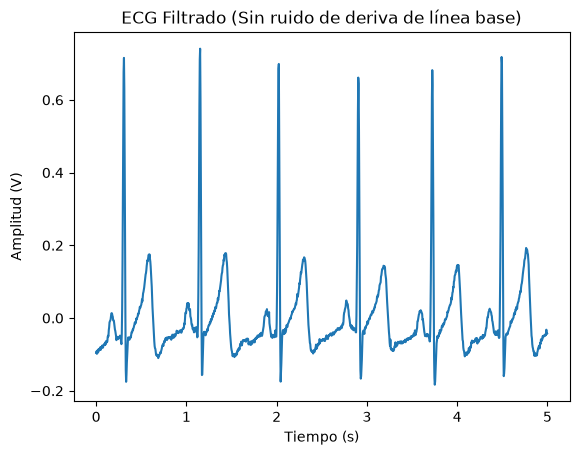

In [45]:
f_corte = 0.5 

# Calcular cuántos bins (índices) corresponden a esas frecuencias bajas
idx_corte = int(f_corte * N / fs)

# 1. Anular el componente DC (índice 0) y las frecuencias bajas positivas
F2[0 : idx_corte + 1] = 0

# 2. Anular las frecuencias simétricas negativas correspondientes
# (Solo si idx_corte es mayor a 0, para evitar errores de sintaxis en el arreglo)
if idx_corte > 0:
    F2[-idx_corte:] = 0

# Reconstruir la señal en el dominio del tiempo
xr = np.fft.ifft(F2)

# Graficar
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)')
plt.title('ECG Filtrado (Sin ruido de deriva de línea base)')
plt.show()

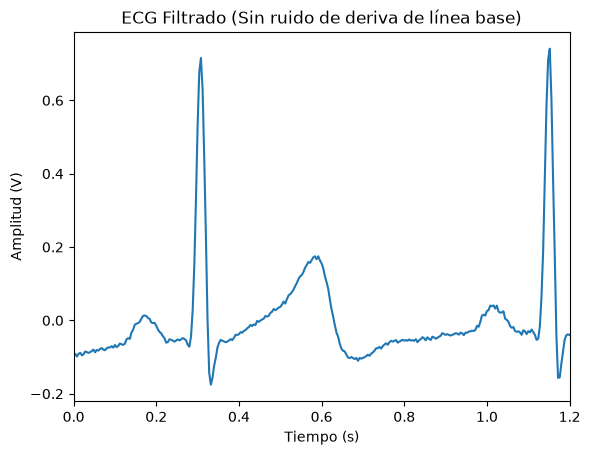

In [52]:
mask = (t >= 0) & (t <= 1.2)

# Graficar únicamente el intervalo seleccionado
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t[mask], np.real(xr)[mask])

ax.set(
    xlabel='Tiempo (s)',
    ylabel='Amplitud (V)',
    xlim=(0, 1.2)
)

plt.title('ECG Filtrado (Sin ruido de deriva de línea base)')
plt.show()

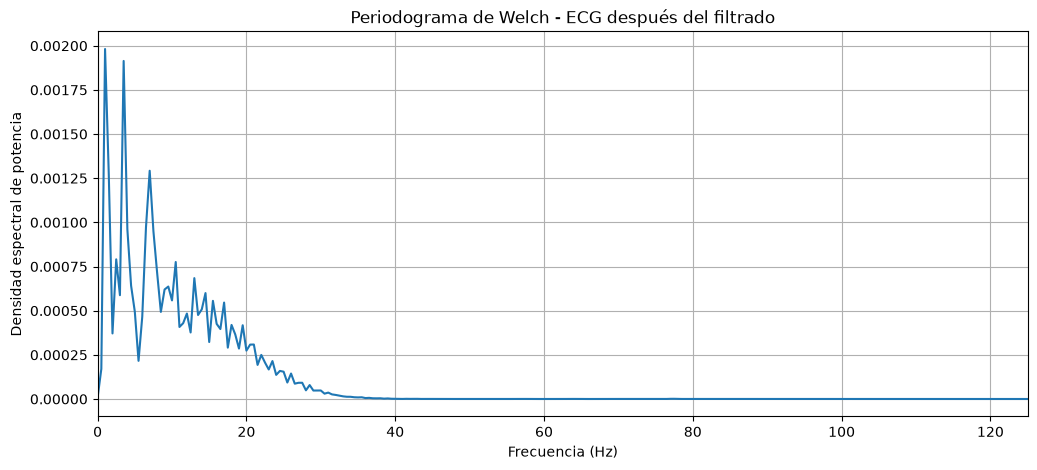

In [54]:
x_filtrada = np.real(xr)

# Parámetros de muestreo
Fs = 250

# Parámetros de Welch
nperseg = 500  
noverlap = 250

# Calcular periodograma de Welch
f, Pxx = welch(
    x_filtrada,
    fs=Fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap,
    detrend=False
)

# Graficar periodograma
plt.figure(figsize=(12, 5))

plt.plot(f, Pxx)

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia')
plt.title('Periodograma de Welch - ECG después del filtrado')
plt.xlim(0, 125)
plt.grid()
plt.show()

Se utilizaron 500 muestras para obtener resolución suficiente y poder observar hasta 0.5 Hz en el periodograma y 250 de solapamiento para obtener un 50% de la longitud del segmento.
Se puede observar que fue correctamente eliminado el ruido de 60 Hz y  el ruido de baja frecuencia correspondiente a la deriva de línea base que se tenía cerca a los 0.5 Hz con un pico en la densidad espectral de potencia de 0.006.
Con la transformada inversa se comprobó que al eliminar el ruido se tivo una mejor visualización de la señal que se tenía y el periodograma permitió confirmar una reducción de la densidad espectral de potencia en las frecuencias que se quería.

7. Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja) (25%)

In [ ]:
import glob
import os
from pathlib import Path
import pandas as pd
import seaborn as sns


In [57]:
RUTA_CARPETA = r"ECGDataDenoised"
DIAGNOSTICS_PATH = r"Diagnostics.xlsx"
FS = 500  # Frecuencia de muestreo (Hz)
DERIVACIONES = [
    'I',
    'II',
    'III',
    'aVR',
    'aVL',
    'aVF',
    'V1',
    'V2',
    'V3',
    'V4',
    'V5',
    'V6',
]

# 1. Cargar el Excel e indexar por 'FileName' para búsquedas instantáneas
diagnostics = pd.read_excel(DIAGNOSTICS_PATH).set_index('FileName')

# 2. Buscar archivos CSV
archivos_csv = glob.glob(os.path.join(RUTA_CARPETA, '*.csv'))
print(f'Procesando {len(archivos_csv)} archivos CSV...')

registros_exploracion = []

for archivo in archivos_csv:
  filename_stem = Path(archivo).stem

  # Búsqueda en el índice del Excel
  if filename_stem in diagnostics.index:
    arritmia = diagnostics.loc[filename_stem, 'Rhythm']

    # Si por alguna razón hay duplicados en el Excel, tomar el primero
    if isinstance(arritmia, pd.Series):
      arritmia = arritmia.iloc[0]

    # Leer CSV indicando header=None para no interpretar la 1ra muestra como encabezado
    df = pd.read_csv(archivo, header=None)
    num_muestras = len(df)
    duracion_seg = num_muestras / FS

    registros_exploracion.append({
        'Archivo': filename_stem,
        'Arritmia': arritmia,
        'Muestras': num_muestras,
        'Duracion_s': duracion_seg,
        'Canales': len(df.columns),
    })

# Crear DataFrame consolidado
df_exploracion = pd.DataFrame(registros_exploracion)

Procesando 10646 archivos CSV...


Se utiliza la librería neurokit2 la cual permite generar una señal de ECG de una persona sana la cual se va a comparar con la de una arritmia AFIB, utilizada en el proyecto anterior cuando se seleccionó un grupo que contenía las personas con AFIB, SR, ST, y SB entre 18 y 74 años.

In [58]:
import neurokit2 as nk

In [78]:
# Parámetros
FS = 500
duracion_deseada = 10
tiempo_calentamiento = 5 # 5 segundos extra para que la matemática se estabilice

# Generar un ECG más largo (15 segundos en total)
ecg_largo = nk.ecg_simulate(
    duration=duracion_deseada + tiempo_calentamiento,
    sampling_rate=FS,
    heart_rate=70,
    heart_rate_std=1,
    noise=0,
    method='ecgsyn',
    random_state=42
)

# Recortar el calentamiento: nos quedamos solo con los últimos 10 segundos
# Multiplicamos los segundos a cortar por la frecuencia de muestreo para obtener el índice
inicio_valido = tiempo_calentamiento * FS
ecg_sano = ecg_largo[inicio_valido:]
ecg_sano = ecg_sano*1000 #Para ponerlo en mV

# Vector de tiempo para los 10 segundos limpios
t_sano = np.arange(len(ecg_sano)) / FS

In [79]:
# Buscar registros con diagnóstico AFIB
candidatos_afib = df_exploracion[
    df_exploracion['Arritmia'].astype(str).str.contains(
        'AFIB', case=False, na=False
    )
].reset_index(drop=True)

# Comprobar que encontramos registros
if candidatos_afib.empty:
    raise ValueError("No se encontraron registros con AFIB")

# Mostrar algunos registros disponibles
print(candidatos_afib[['Archivo', 'Arritmia', 'Duracion_s']].head(10))

                      Archivo Arritmia  Duracion_s
0  MUSE_20180111_155154_74000     AFIB        10.0
1  MUSE_20180111_155203_15000     AFIB        10.0
2  MUSE_20180111_155903_57000     AFIB        10.0
3  MUSE_20180111_155945_02000     AFIB        10.0
4  MUSE_20180111_160053_89000     AFIB        10.0
5  MUSE_20180111_160110_47000     AFIB        10.0
6  MUSE_20180111_160117_84000     AFIB        10.0
7  MUSE_20180111_160140_78000     AFIB        10.0
8  MUSE_20180111_160159_36000     AFIB        10.0
9  MUSE_20180111_160201_47000     AFIB        10.0


In [80]:

registro_afib = candidatos_afib.iloc[0]

# Obtener nombre del archivo
nombre_archivo = registro_afib['Archivo']

# Construir ruta
ruta_afib = os.path.join(
    RUTA_CARPETA,
    nombre_archivo + '.csv'
)

# Leer señal
df_afib = pd.read_csv(ruta_afib, header=None)

# Extraer segunda derivación (DII)
indice_II = DERIVACIONES.index('II')

ecg_AFIB = df_afib.iloc[:, indice_II].to_numpy(dtype=float)

print("Archivo seleccionado:", nombre_archivo)
print("Diagnóstico:", registro_afib['Arritmia'])
print("Número de muestras:", len(ecg_AFIB))
print("Duración:", len(ecg_AFIB)/FS, "segundos")

Archivo seleccionado: MUSE_20180111_155154_74000
Diagnóstico: AFIB
Número de muestras: 5000
Duración: 10.0 segundos


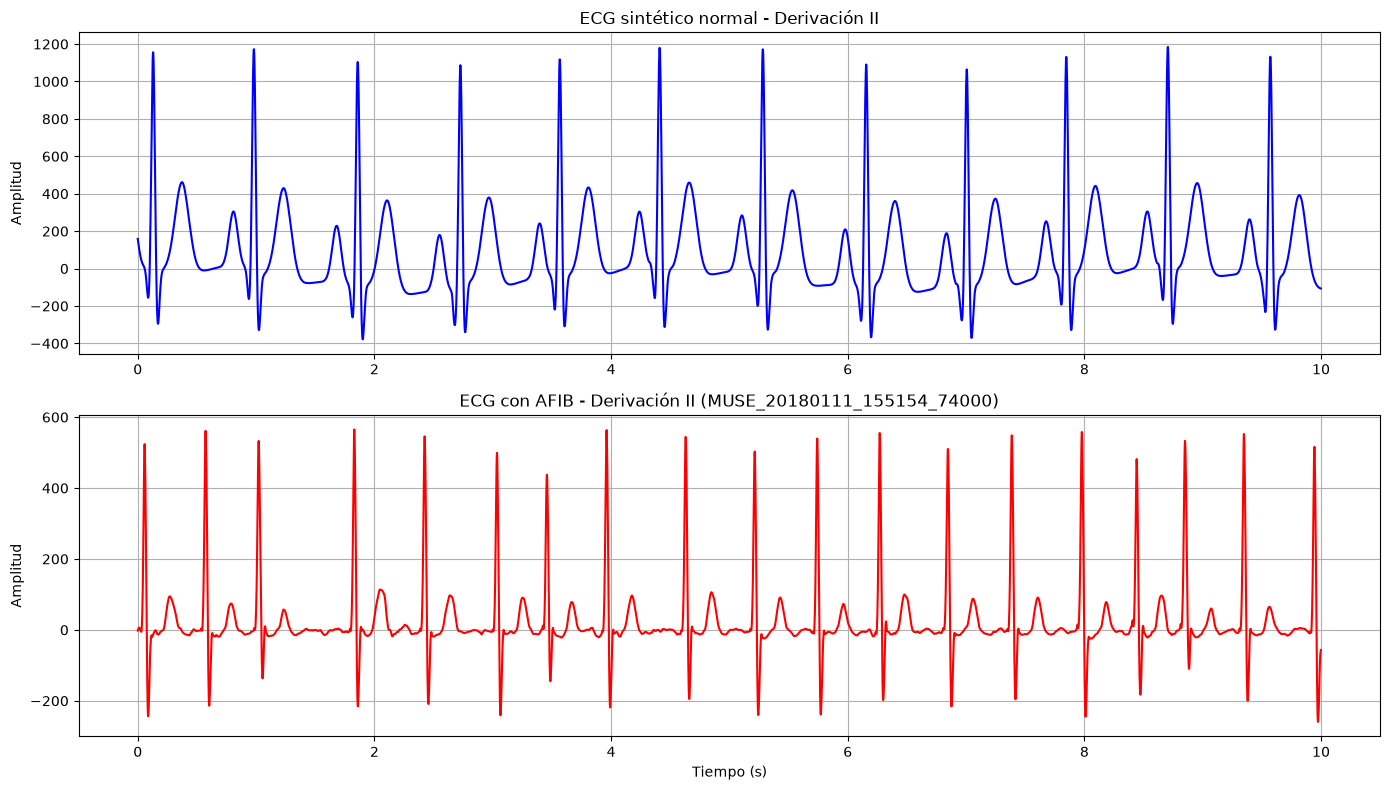

In [81]:
# Determinar cantidad de muestras para comparar
N = min(
    len(ecg_sano),
    len(ecg_AFIB),
    int(10 * FS)
)

# Recortar ambas señales
ecg_sano_plot = ecg_sano[:N]
ecg_AFIB_plot = ecg_AFIB[:N]

# Vector de tiempo común
t = np.arange(N) / FS

# Graficar
plt.figure(figsize=(14, 8))

# ECG sano
plt.subplot(2, 1, 1)
plt.plot(t, ecg_sano_plot, color='blue')
plt.title('ECG sintético normal - Derivación II')
plt.ylabel('Amplitud')
plt.grid()

# ECG con AFIB
plt.subplot(2, 1, 2)
plt.plot(t, ecg_AFIB_plot, color='red')
plt.title(f'ECG con AFIB - Derivación II ({nombre_archivo})')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid()

plt.tight_layout()
plt.show()

Dimensiones ECG sano: (5000,)
Dimensiones ECG AFIB: (5000,)


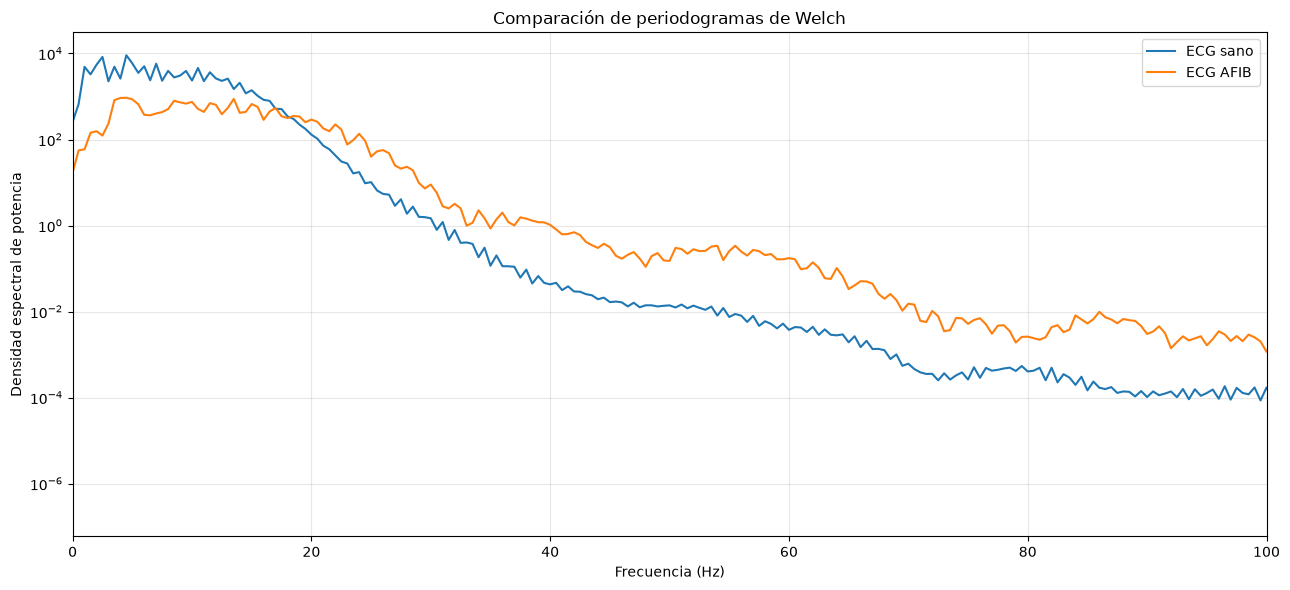

Duración analizada: 10.0 segundos
Resolución frecuencial: 0.5 Hz
Número de segmentos: 9


In [ ]:
# Frecuencia de muestreo
FS = 500

# Asegurar vectores unidimensionales
ecg_sano = np.asarray(ecg_sano).squeeze().astype(float)
ecg_AFIB = np.asarray(ecg_AFIB).squeeze().astype(float)

# Comprobar dimensiones
print("Dimensiones ECG sano:", ecg_sano.shape)
print("Dimensiones ECG AFIB:", ecg_AFIB.shape)

# Comprobar valores no válidos
if not np.all(np.isfinite(ecg_sano)) or not np.all(np.isfinite(ecg_AFIB)):
    raise ValueError("Hay valores NaN o infinitos en alguna señal.")

# Seleccionar primeros 10 segundos
N = min(len(ecg_sano), len(ecg_AFIB), 10 * FS)

ecg_sano_comp = ecg_sano[:N]
ecg_AFIB_comp = ecg_AFIB[:N]

# Parámetros de Welch
nperseg = 1000
noverlap = 500

if N < nperseg:
    raise ValueError("No hay suficientes muestras.")

# Calcular Welch - ECG sano
f_sano, P_sano = welch(
    ecg_sano_comp,
    fs=FS,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)

# Calcular Welch - ECG AFIB
f_AFIB, P_AFIB = welch(
    ecg_AFIB_comp,
    fs=FS,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)

# Graficar
plt.figure(figsize=(13, 6))

plt.semilogy(f_sano, P_sano, label='ECG sano')
plt.semilogy(f_AFIB, P_AFIB, label='ECG AFIB')

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia')
plt.title('Comparación de periodogramas de Welch')

plt.xlim(0, 100)
plt.legend()
plt.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

print("Duración analizada:", N/FS, "segundos")
print("Resolución frecuencial:", FS/nperseg, "Hz")
print("Número de segmentos:", 1 + (N-nperseg)//(nperseg-noverlap))

Es importante aclarar que al utilizar la librería Neurokit2 y generar una señal de un "paciente sano" de manera artificial, no se busca obtener un resultado que permita diferenciar de manera general entre pacientes sanos y pacientes con arritmia (AFIB), sino hacer el análisis para este caso de las diferencias entre los periodogramas de welch.

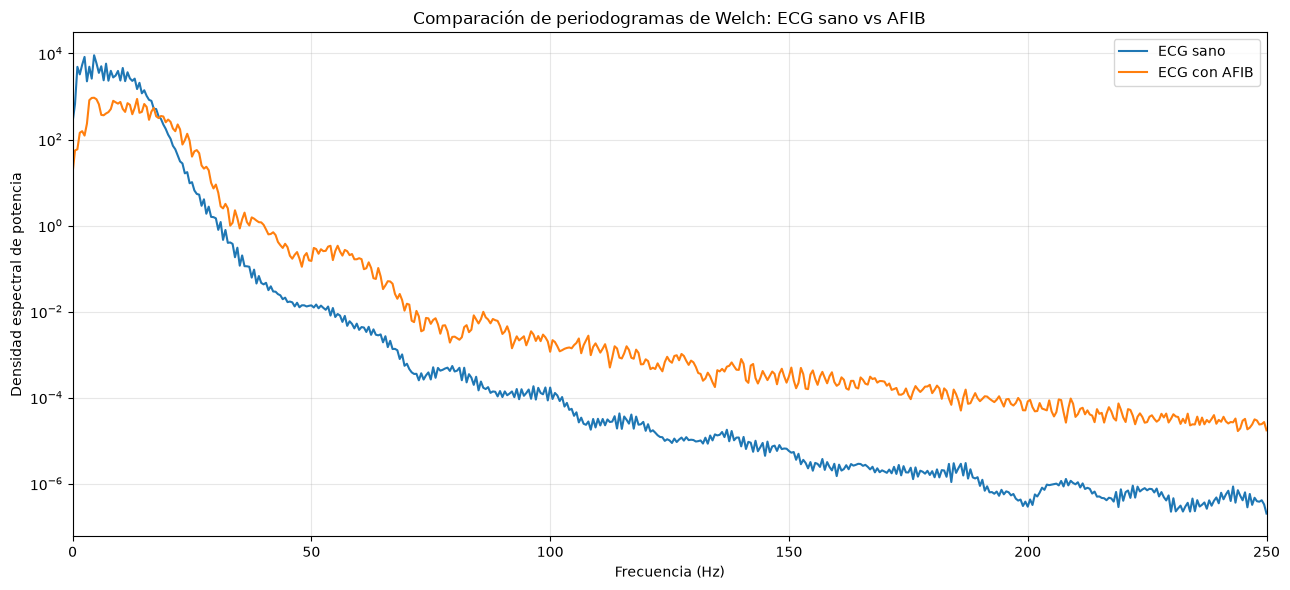

In [82]:
# Frecuencia de muestreo
Fs = 500

# Asegurar que ambas señales sean vectores unidimensionales
ecg_sano = np.asarray(ecg_sano).squeeze()
ecg_AFIB = np.asarray(ecg_AFIB).squeeze()


N = min(len(ecg_sano), len(ecg_AFIB), 10 * Fs)

ecg_sano_comp = ecg_sano[:N]
ecg_AFIB_comp = ecg_AFIB[:N]

# Parámetros de Welch
nperseg = 1000
noverlap = 500

if N < nperseg:
    raise ValueError("Las señales deben tener al menos 1000 muestras.")


f_sano, P_sano = welch(
    ecg_sano_comp,
    fs=Fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)

f_AFIB, P_AFIB = welch(
    ecg_AFIB_comp,
    fs=Fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)


plt.figure(figsize=(13, 6))

plt.semilogy(f_sano, P_sano, label='ECG sano', linewidth=1.5)
plt.semilogy(f_AFIB, P_AFIB, label='ECG con AFIB', linewidth=1.5)

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia')
plt.title('Comparación de periodogramas de Welch: ECG sano vs AFIB')

plt.xlim(0, Fs/2)

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

Acercamiento a frecuencias menores a 50 Hz:

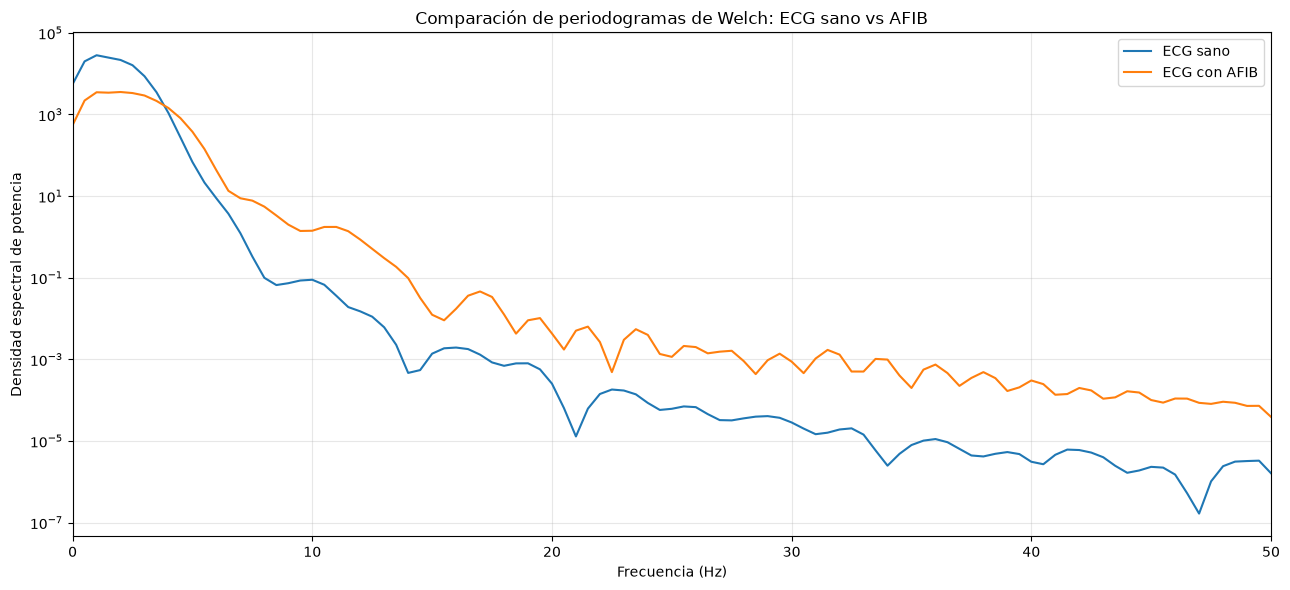

In [88]:
# Frecuencia de muestreo
Fs = 100

# Asegurar que ambas señales sean vectores unidimensionales
ecg_sano = np.asarray(ecg_sano).squeeze()
ecg_AFIB = np.asarray(ecg_AFIB).squeeze()


N = min(len(ecg_sano), len(ecg_AFIB), 10 * Fs)

ecg_sano_comp = ecg_sano[:N]
ecg_AFIB_comp = ecg_AFIB[:N]

# Parámetros de Welch
nperseg = 200
noverlap = 100

if N < nperseg:
    raise ValueError("Las señales deben tener al menos 1000 muestras.")


f_sano, P_sano = welch(
    ecg_sano_comp,
    fs=Fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)

f_AFIB, P_AFIB = welch(
    ecg_AFIB_comp,
    fs=Fs,
    window='hann',
    nperseg=nperseg,
    noverlap=noverlap
)


plt.figure(figsize=(13, 6))

plt.semilogy(f_sano, P_sano, label='ECG sano', linewidth=1.5)
plt.semilogy(f_AFIB, P_AFIB, label='ECG con AFIB', linewidth=1.5)

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia')
plt.title('Comparación de periodogramas de Welch: ECG sano vs AFIB')

plt.xlim(0, Fs/2)

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

Para analizar el gráfico primero se debe considerar la escala del eje y el cual da la densidad espectral de potencia. Debido a que se analizaron las señales en mV y por la fórmula utilizada se eleva la amplitud al cuadrado lo que resulta en una gran amplitud.

Primeramente, considerando una descripción de ambos gráficos se puede observar por la escala de las potencias en la densidad espectral de potencia que la mayoría de la potencia de las señales en ambos casos se encuentra a menos de 50 Hz, mientras que para frecuencias altas las señales casi no presentan energía.


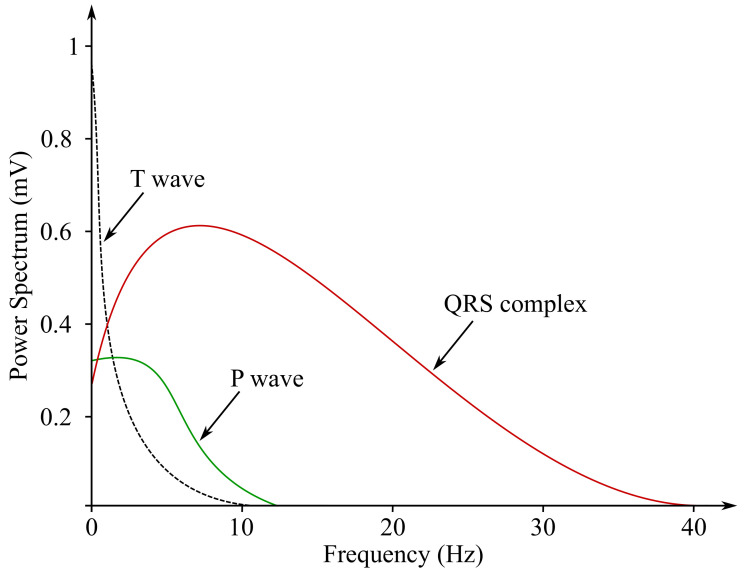

Figura 1. Representación de las frecuencias de las ondas del ECG. Tomado de [4]


Se pueden analizar los rangos de frecuencia que corresponden a las diferentes ondas del ECG de la Figura 1, la onda T se encuentra en frecuencias menores a 10 Hz pero está centrada alrededor de 0 a 3 Hz. Por otro lado, la onda P tiene el rango de frecuencias de 0 a 12 Hz con una mayor concentración entre 0 a 5 Hz.
Es en estos rangos de mayor presencia de las ondas P y T que la señal del ECG sano tiene mayor potencia que la señal AFIB, cosa que concuerda con lo observado en el gráfico ya que las ondas P y T en la señal AFIB tienen menor amplitud y considerando la afectación de la señal de las aurículas en la AFIB.

Es importante también analizar el complejo QRS, el cual como se observa en la figura 1 va desde los 0 a los 40 Hz aproximadamente y su distrbución no está tan concentrada en unas frecuencias como la onda P y T aunque tenga una mayor concentración de 0 a 20 Hz. Considerando esto y la afectación en el bombeo de las aurículas en la señal con fibrilación se puede analizar por qué desde los 7 a 10 Hz aproximadamente la señal AFIB tiene más potencia que la señal sana. 
Con un sistema eléctrico que no está sincronizado, la potencia se distribuye más en el rango de frecuencia, a diferencia de la señal sana que está más concentrado entre 0 a 10 Hz, ya que la energía se dispersa por los impulsos caóticos que se generan.



**Conclusiones**

1. 




2.  El uso del periodograma de Welch en conjunto con la señal de ECG sana idealizada generada con la librería neurokit2 es una herramienta efectiva para evidenciar la desorganización eléctrica que se tiene con la fibrilación auricular (AFIB) en el dominio de la frecuencia. Mientras que el modelo sano idealizado concentra su mayor potencia entre 0 y 10 Hz debido a la sincronización de las ondas cardíacas, la señal AFIB permite observar el colapso de esa sincronización por causas como la reducción de la energía de las ondas P y T y la dispersión de dicha energía en el resto de la señal. Esto permite considerar la variable de la densidad espectral de potencia en el análisis y diagnóstico de arritmias cardíacas.



**Referencias**

[1] NumPy Developers. (s. f.). numpy.fft.ifft — NumPy documentation. https://numpy.org/doc/stable/reference/generated/numpy.fft.ifft.html

[2] P. Welch, "The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms," in IEEE Transactions on Audio and Electroacoustics, vol. 15, no. 2, pp. 70-73, June 1967, doi: 10.1109/TAU.1967.1161901.

[3] Comisión de Regulación de Energía y Gas (CREG), “Concepto 246 de 2024,” Bogotá, D. C., Colombia, ene. 12, 2024. [En línea]. Disponible en: https://gestornormativo.creg.gov.co/gestor/entorno/docs/concepto_creg_0000246_2024.htm

[4] A. Zyout, H. Alquran, W. A. Mustafa, and A. M. Alqudah, “Advanced Time-Frequency Methods for ECG Waves Recognition,” Diagnostics, vol. 13, no. 2, Art. no. 308, Jan. 2023, doi: 10.3390/diagnostics13020308. [Online]. Available: https://pmc.ncbi.nlm.nih.gov/articles/PMC9858079/